# Data preprocessing

This notebook cuts a **4096 × 4096 pixel** area from the centre of the Sentinel-2 scene and saves it as one file, `data/ndvi_input_4096.npz` (about 64 MB). 

Purpose: Small and easier data to handle; Instead of all 10 members downloading about 300 MB of satellite files and installing an image library, cut a 4096×4096 area once and shares a single small file. Members then only need NumPy. Sizes 1024, 2048 and 4096 come from this file. 

In [1]:
%pip install numpy rasterio matplotlib

  Using cached affine-3.0.1-py3-none-any.whl.metadata (4.5 kB)
   ---------------------------------------- 0.0/30.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/30.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/30.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/30.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/30.7 MB ? eta -:--:--
    --------------------------------------- 0.5/30.7 MB 1.1 MB/s eta 0:00:27
   - -------------------------------------- 0.8/30.7 MB 1.3 MB/s eta 0:00:23
   - -------------------------------------- 1.0/30.7 MB 1.3 MB/s eta 0:00:24
   - -------------------------------------- 1.3/30.7 MB 1.3 MB/s eta 0:00:24
   -- ------------------------------------- 1.6/30.7 MB 1.3 MB/s eta 0:00:23
   -- ------------------------------------- 1.8/30.7 MB 1.3 MB/s eta 0:00:23
   -- ------------------------------------- 2.1/30.7 MB 1.3 MB/s eta 0:00:22
   --- ------------------------------------ 2.4/


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = PROJECT / "data"

import re
import numpy as np
import rasterio
from rasterio.windows import Window

RED_FILE = DATA / "sentinel2" / "B04_10m.jp2"
NIR_FILE = DATA / "sentinel2" / "B08_10m.jp2"
META_FILE = DATA / "sentinel2" / "MTD_MSIL2A.xml"
OUT_FILE = DATA / "ndvi_input_4096.npz"
SIZE = 4096

## 1. Read the scaling values from the metadata
Reflectance = (DN + offset) / 10000. The offset is −1000 for products processed since 2022, and 0 for older ones.

In [3]:
xml = META_FILE.read_text(encoding="utf-8")
quant = float(re.search(r"<BOA_QUANTIFICATION_VALUE[^>]*>([\d.]+)<", xml).group(1))
offsets = dict(re.findall(r'<BOA_ADD_OFFSET band_id="(\d+)">(-?[\d.]+)<', xml))
red_offset = float(offsets.get("3", 0))   # B04
nir_offset = float(offsets.get("7", 0))   # B08
product = re.search(r"<PRODUCT_URI>([^<]+)<", xml)
product = product.group(1) if product else "unknown"
print("Product:", product)
print(f"Quantification = {quant}, offset B04 = {red_offset}, offset B08 = {nir_offset}")

Product: S2C_MSIL2A_20260930T070701_N0513_R106_T39RVK_20260930T122704.SAFE
Quantification = 10000.0, offset B04 = -1000.0, offset B08 = -1000.0


## 2. Cut the centre 4096 × 4096 area from both bands

In [4]:
with rasterio.open(RED_FILE) as red_ds, rasterio.open(NIR_FILE) as nir_ds:
    print("Full scene:", red_ds.height, "x", red_ds.width, "pixels")
    # centre, snapped to the file's 1024-px blocks (faster to read)
    block = red_ds.block_shapes[0][0]
    row = (red_ds.height - SIZE) // 2 // block * block
    col = (red_ds.width - SIZE) // 2 // block * block
    window = Window(col, row, SIZE, SIZE)
    red = red_ds.read(1, window=window)
    nir = nir_ds.read(1, window=window)

empty = 100 * np.mean((red == 0) | (nir == 0))
print(f"Cut at row {row}, col {col}: {red.shape}, dtype {red.dtype}, empty pixels {empty:.1f}%")
if empty > 20:
    print("WARNING: many empty pixels - consider another scene or area.")

Full scene: 10980 x 10980 pixels
Cut at row 3072, col 3072: (4096, 4096), dtype uint16, empty pixels 0.0%


## 3. Quick look, then save

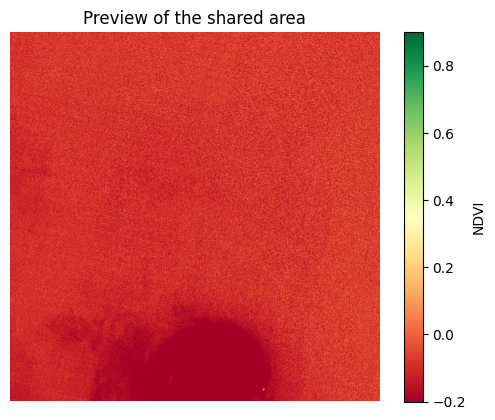

In [5]:
import matplotlib.pyplot as plt
r = (red.astype(np.float32) + red_offset) / quant
n = (nir.astype(np.float32) + nir_offset) / quant
with np.errstate(divide="ignore", invalid="ignore"):
    preview = (n - r) / (n + r)
plt.imshow(preview[::4, ::4], cmap="RdYlGn", vmin=-0.2, vmax=0.9)
plt.colorbar(label="NDVI"); plt.title("Preview of the shared area"); plt.axis("off"); plt.show()

In [6]:
np.savez(OUT_FILE, red=red, nir=nir, quant=quant, red_offset=red_offset,
         nir_offset=nir_offset, product=product, row=row, col=col)
print(f"Saved {OUT_FILE} ({OUT_FILE.stat().st_size / 1e6:.0f} MB) - upload it to the team drive.")

Saved c:\Users\Reena\OneDrive\Documents\Parallel-Satellite-Image-Analysis_Code\data\ndvi_input_4096.npz (67 MB) - upload it to the team drive.
